In [ ]:
# Execute this cell first to import libraries and generate the dataset
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_circles

X, y = make_circles(n_samples=1000, factor=0.9, noise=0.2, random_state=0)
print("Dataset X and y generated successfully. Libraries imported.")

Dataset X and y generated successfully. Libraries imported.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Week-2

**Note to Learners**:

- For questions that involve plotting, just enter $0$ as the answer in the portal.
- For numerical questions, there are two parts. The first part expects you to compute some quantity, say a parameter of a machine learning model. The second part will require you to convert this quantity (if it is not a scalar) into a scalar so that it can be entered as the answer on the portal to the corresponding NAT question.



## Dataset

Run the cell given below to generate the data-matrix $\mathbf{X}$, which is of shape $(n, d)$, where $n$ denotes the number of samples and $d$ denotes the number of features. Ignore the vector $y$. You will be using this dataset for the rest of the assignment. Do not edit this cell.

In [ ]:
from sklearn.datasets import make_circles

X, y = make_circles(n_samples=1000, factor=0.9, noise=0.2, random_state=0)

## Problem 1
Plot the dataset using matplotlib.

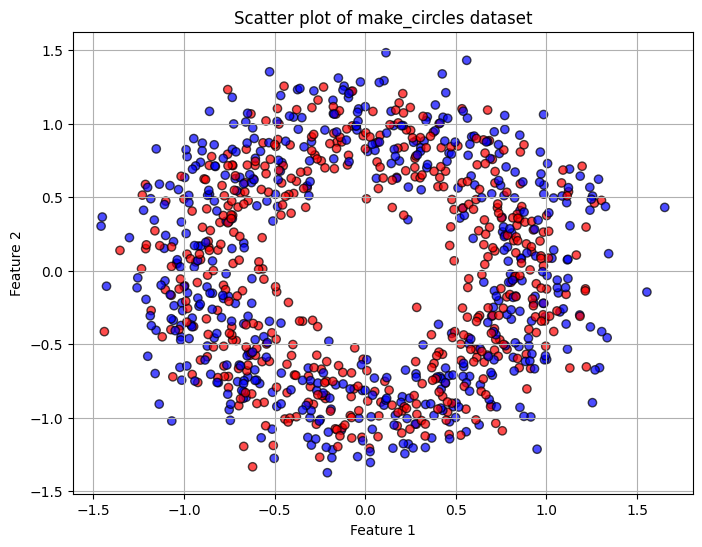

In [ ]:
# Problem 1: Plotting the dataset using matplotlib
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap='bwr', alpha=0.7, edgecolors='k')
plt.title('Scatter plot of make_circles dataset')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.grid(True)
plt.show()

## Problem 2
How many samples are there in the dataset?


In [ ]:
# Problem 2: Number of samples in the dataset
n_samples = X.shape[0]
print(f"Number of samples (n): {n_samples}")

Number of samples (n): 1000


## Problem 3
How many features are there in the dataset?

In [ ]:
# Problem 3: Number of features in the dataset
n_features = X.shape[1]
print(f"Number of features (d): {n_features}")

Number of features (d): 2


## Problem 4
Find the kernel matrix $K$ using the polynomial kernel with degree $2$.

<u>Conversion</u>

Enter the following quantity as your answer correct to two decimal places:

$$
\cfrac{1}{n} \sqrt{\sum \limits_{i = 1}^{n} \sum \limits_{j = 1}^{n} (K_{ij})^2}
$$

In [ ]:
# Problem 4: Polynomial kernel with degree 2
# K(x, y) = (x^T y + 1)^d
K_poly = (X @ X.T + 1) ** 2

# Conversion
ans_poly = (1 / n_samples) * np.sqrt(np.sum(K_poly ** 2))
print(f"Polynomial Kernel Conversion Answer: {ans_poly:.2f}")

Polynomial Kernel Conversion Answer: 2.10


## Problem 5
Find the kernel matrix $K$ using the Gaussian kernel with parameter $\sigma = 2$.

<u>Conversion</u>

Enter the following quantity as your answer correct to two decimal places:

$$
\cfrac{1}{n} \sqrt{\sum \limits_{i = 1}^{n} \sum \limits_{j = 1}^{n} (K_{ij})^2}
$$

In [ ]:
# Problem 5: Gaussian kernel with sigma = 2
# K(x, y) = exp(-||x - y||^2 / (2 * sigma^2))
sq_dists = np.sum(X**2, axis=1, keepdims=True) + np.sum(X**2, axis=1) - 2 * (X @ X.T)
sigma = 2
K_rbf = np.exp(-sq_dists / (2 * (sigma ** 2)))

# Conversion
ans_rbf = (1 / n_samples) * np.sqrt(np.sum(K_rbf ** 2))
print(f"Gaussian Kernel Conversion Answer: {ans_rbf:.2f}")

Gaussian Kernel Conversion Answer: 0.81


## Problem 6
Find the center of the kernel matrix $K$ obtained in problem 2. Call this centered matrix $KC$.

<u>Conversion</u>

Enter the following quantity as your answer correct to two decimal places:

$$
\cfrac{1}{n} \sqrt{\sum \limits_{i = 1}^{n} \sum \limits_{j = 1}^{n} KC_{ij}^2}
$$

In [ ]:
# Problem 6: Centered kernel matrix of Problem 4
# Centering: KC = K - 1_N * K - K * 1_N + 1_N * K * 1_N
# where 1_N is a matrix with all elements equal to 1/N
N = n_samples
I_N = np.ones((N, N)) / N
KC = K_poly - I_N @ K_poly - K_poly @ I_N + I_N @ K_poly @ I_N

# Conversion
ans_kc = (1 / N) * np.sqrt(np.sum(KC ** 2))
print(f"Centered Kernel Conversion Answer: {ans_kc:.2f}")

Centered Kernel Conversion Answer: 1.45


## Problem 7
Find the projections (scalar) of all the data points on to the first two principal components obtained using polynomial kernel of degree 2.

<u>Conversion</u>

if $\alpha_1, \alpha_2, ..., \alpha_n$ are the prjections on the first PC and $\beta_1, \beta_2, ..., \beta_n$ are the projections on the second PC, enter the following quantity as your answer correct to two decimal places:

$$\sum_{i = 1}^{n} \alpha_i + \sum_{i = 1}^{n} \beta_i$$

In [ ]:
# Problem 7: Projections onto the first two PCs using the polynomial kernel of degree 2
# Using the centered polynomial kernel matrix KC
eigenvalues, eigenvectors = np.linalg.eigh(KC)

# Sort in descending order of eigenvalues
idx = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[idx]
eigenvectors = eigenvectors[:, idx]

# Filter out extremely small eigenvalues to avoid division by zero/numerical issues
eig_1, eig_2 = eigenvalues[0], eigenvalues[1]
alpha_norm = eigenvectors[:, 0] / np.sqrt(eig_1)
beta_norm = eigenvectors[:, 1] / np.sqrt(eig_2)

# Projection of data points onto the eigenvectors of KC
projection_1 = KC @ alpha_norm
projection_2 = KC @ beta_norm

ans_proj = np.sum(projection_1) + np.sum(projection_2)
print(f"Projections Sum Answer: {ans_proj:.2f}")

Projections Sum Answer: 0.00
